In [1]:
import pandas as pd
from db_queries import get_location_metadata
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import numpy as np
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import yaml

# Set paths ####################################################################
RAW_DATA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_09_13.01/data.parquet"
GBD_FILE = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/gbd_prevalence/gbd_mean_neonatal_mortality_prevalence.parquet"
INFERENCE_FILE_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_14.01/ssp245.parquet"  # Consumption merged on birth year
RESULTS_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_14.02/"  # .01 is the input spec; .02 is the fit

RESULTS_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_21.02/"
RESULTS_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_22.02/"
RESULTS_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.02/"  # birth_year dropped, consumption_median_RT rescaled to $/day
RESULTS_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.03/"  # birth_year dropped, consumption_median_RT, climate variables included


INFERENCE_FILE_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.01/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
INFERENCE_FILE_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.02/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
INFERENCE_FILE_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.01/ssp245.parquet"  # model 2026_09_23.02: consumption_median_RT (LDI based), no birth_year
INFERENCE_FILE_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.02/ssp245.parquet"  # model 2026_09_24: birth_year dropped, consumption_median_RT, climate variables included
PLOT_OUTPUT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/"


df_raw = pd.read_parquet(RAW_DATA_PATH)

# Add location names
locs = get_location_metadata(location_set_id=39, release_id=16)

df_raw = df_raw.merge(
    locs[["location_id", "location_name", "level", "super_region_name"]],
    on="location_id",
    how="left",
)

df_raw.head()

,year_start,year_end,nid,survey_name,int_year,int_month,sex_id,mothers_age_year,aod_months,age_month,...,year_id,age_group_id,int_birth_year_diff_months,log_consumption_pd,sdi,consumption_pd_national_median,consumption_median_RT,location_name,level,super_region_name
0,2009,2010,13109,DHS_MIS,None,None,2,None,0,0,...,2009,42,0,-0.245692,0.318291,2.179549,2.361256,Uganda,3,Sub-Saharan Africa
1,2022,2022,538795,None,2022,5,2,18,0,0,...,2021,42,11,1.312609,0.447416,3.220460,3.404259,United Republic of Tanzania,3,Sub-Saharan Africa
2,2017,2017,353526,None,2017,4,1,20,0,0,...,2017,42,0,2.448691,0.373539,3.087602,4.210878,Senegal,3,Sub-Saharan Africa
3,2019,2021,467681,DHS,None,None,1,None,0,0,...,2020,42,2,1.619791,0.583046,4.671741,5.111802,India,3,South Asia
4,2000,2000,19156,None,2000,2,2,24,0,0,...,1999,42,2,-0.227447,0.340183,1.772798,2.106530,Cambodia,3,"Southeast Asia, East Asia, and Oceania"


In [2]:
# Parametric fixed effects, compared across model runs #######################
# base_model_coefs.parquet holds only the parametric terms. A spline on
# consumption_pd is not in there - its partial effect lives in
# spline_effect_consumption_pd.parquet - so these tables are exactly the
# non-spline fixed effects.
#
# A run that has not finished yet is skipped with a note rather than raising,
# so the fourth slot can be filled in by pointing RESULTS_09_23 at the run and
# re-executing once it lands.
COEF_MODELS = {
    "RESULTS_09_14": RESULTS_09_14,
    "RESULTS_09_21": RESULTS_09_21,
    "RESULTS_09_22": RESULTS_09_22,
    "RESULTS_09_23": RESULTS_09_23,
    "RESULTS_09_24": RESULTS_09_24,
}
COEF_COLUMNS = ["term", "Estimate", "std_error", "p_value", "signif"]

coef_tables = {}
_coef_long = []
for _name, _path in COEF_MODELS.items():
    _dir = Path(_path)
    if not (_dir / "base_model_coefs.parquet").exists():
        print(f"{_name}: no base_model_coefs.parquet yet at {_dir}\n")
        continue

    _spec = yaml.safe_load((_dir / "specification.yaml").read_text())
    _tab = pd.read_parquet(_dir / "base_model_coefs.parquet").reset_index()
    _tab["signif"] = pd.cut(
        _tab["p_value"],
        bins=[-0.001, 0.001, 0.01, 0.05, 1.0],
        labels=["***", "**", "*", ""],
    ).astype(str)
    _tab = _tab[COEF_COLUMNS].round({"Estimate": 5, "std_error": 5, "p_value": 4})

    _ranef = pd.read_parquet(_dir / "base_model_ranef.parquet")
    _splines = [p["name"] for p in _spec["predictors"] if p.get("spline")]
    print(
        f"{_name}  ({_dir.name}): {len(_tab)} parametric fixed effects; "
        f"training data {_spec['version']['training_data']}\n"
        f"  spline terms not shown: {', '.join(_splines) if _splines else 'none'}\n"
        f"  random intercept on ihme_loc_id: {len(_ranef)} countries, "
        f"sd {_ranef['offset'].std():.4f}, "
        f"range {_ranef['offset'].min():+.3f} to {_ranef['offset'].max():+.3f}"
    )
    display(_tab)
    print()

    coef_tables[_name] = _tab
    _coef_long.append(_tab.assign(model=_name))

# Side by side, so a term can be read across runs. Terms that a run did not
# include come back NaN, which is the point: it shows what entered when.
coef_compare = (
    pd.concat(_coef_long)
    .pivot(index="term", columns="model", values=["Estimate", "p_value", "signif"])
    .swaplevel(axis=1)
    .reindex(
        columns=pd.MultiIndex.from_product(
            [list(coef_tables), ["Estimate", "p_value", "signif"]]
        )
    )
)
print(f"Estimates across {len(coef_tables)} runs:")
coef_compare

RESULTS_09_14  (2026_09_14.02): 3 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd
  random intercept on ihme_loc_id: 60 countries, sd 0.3961, range -1.442 to +0.606


,term,Estimate,std_error,p_value,signif
0,(Intercept),33.15694,1.55841,0.0,***
1,C(sex_id)2,-0.26264,0.00905,0.0,***
2,birth_year,-0.01827,0.00077,0.0,***



RESULTS_09_21  (2026_09_21.02): 4 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd
  random intercept on ihme_loc_id: 60 countries, sd 0.3877, range -1.416 to +0.610


,term,Estimate,std_error,p_value,signif
0,(Intercept),31.86277,2.05290,0.0000,***
1,C(sex_id)2,-0.26266,0.00905,0.0000,***
2,birth_year,-0.01760,0.00104,0.0000,***
3,consumption_pd_national_median,-0.03904,0.04034,0.3332,



RESULTS_09_22  (2026_09_22.02): 3 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd
  random intercept on ihme_loc_id: 60 countries, sd 0.3452, range -0.997 to +0.637


,term,Estimate,std_error,p_value,signif
0,(Intercept),-2.96831,0.07954,0.0,***
1,C(sex_id)2,-0.26259,0.00905,0.0,***
2,consumption_pd_national_median,-0.49452,0.03009,0.0,***


... (2 outputs left out)


RESULTS_09_24  (2026_09_23.03): 4 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd, days_over_30C_prev_0_mo
  random intercept on ihme_loc_id: 60 countries, sd 0.3650, range -1.025 to +0.613


,term,Estimate,std_error,p_value,signif
0,(Intercept),-2.76175,0.07614,0.0,***
1,C(sex_id)2,-0.26236,0.00905,0.0,***
2,consumption_median_RT,-0.58541,0.02891,0.0,***
3,total_precipitation_prev_0_mo,-0.00398,0.00079,0.0,***



Estimates across 5 runs:


RESULTS_09_14                RESULTS_09_21  \
                                    Estimate p_value signif      Estimate   
term                                                                        
(Intercept)                         33.15694     0.0    ***      31.86277   
C(sex_id)2                          -0.26264     0.0    ***      -0.26266   
birth_year                          -0.01827     0.0    ***       -0.0176   
consumption_median_RT                    NaN     NaN    NaN           NaN   
consumption_pd_national_median           NaN     NaN    NaN      -0.03904   
total_precipitation_prev_0_mo            NaN     NaN    NaN           NaN   

                                              RESULTS_09_22                 \
                               p_value signif      Estimate p_value signif   
term                                                                         
(Intercept)                        0.0    ***      -2.96831     0.0    ***   
C(sex_id)2                         0.0    ***      -0.26259     0.0    ***   
birth_year                         0.0    ***           NaN     NaN    NaN   
consumption_median_RT              NaN    NaN           NaN     NaN    NaN   
consumption_pd_national_median  0.3332             -0.49452     0.0    ***   
total_precipitation_prev_0_mo      NaN    NaN           NaN     NaN    NaN   

                               RESULTS_09_23                RESULTS_09_24  \
                                    Estimate p_value signif      Estimate   
term                                                                        
(Intercept)                         -2.80158     0.0    ***      -2.76175   
C(sex_id)2                          -0.26257     0.0    ***      -0.26236   
birth_year                               NaN     NaN    NaN           NaN   
consumption_median_RT               -0.57601     0.0    ***      -0.58541   
consumption_pd_national_median           NaN     NaN    NaN           NaN   
total_precipitation_prev_0_mo            NaN     NaN    NaN      -0.00398   

                                               
                               p_value signif  
term                                           
(Intercept)                        0.0    ***  
C(sex_id)2                         0.0    ***  
birth_year                         NaN    NaN  
consumption_median_RT              0.0    ***  
consumption_pd_national_median     NaN    NaN  
total_precipitation_prev_0_mo      0.0    ***

9,870 country-years across 470 countries, 2000-2020, 6 series
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/predictions_four_runs_three_countries.pdf


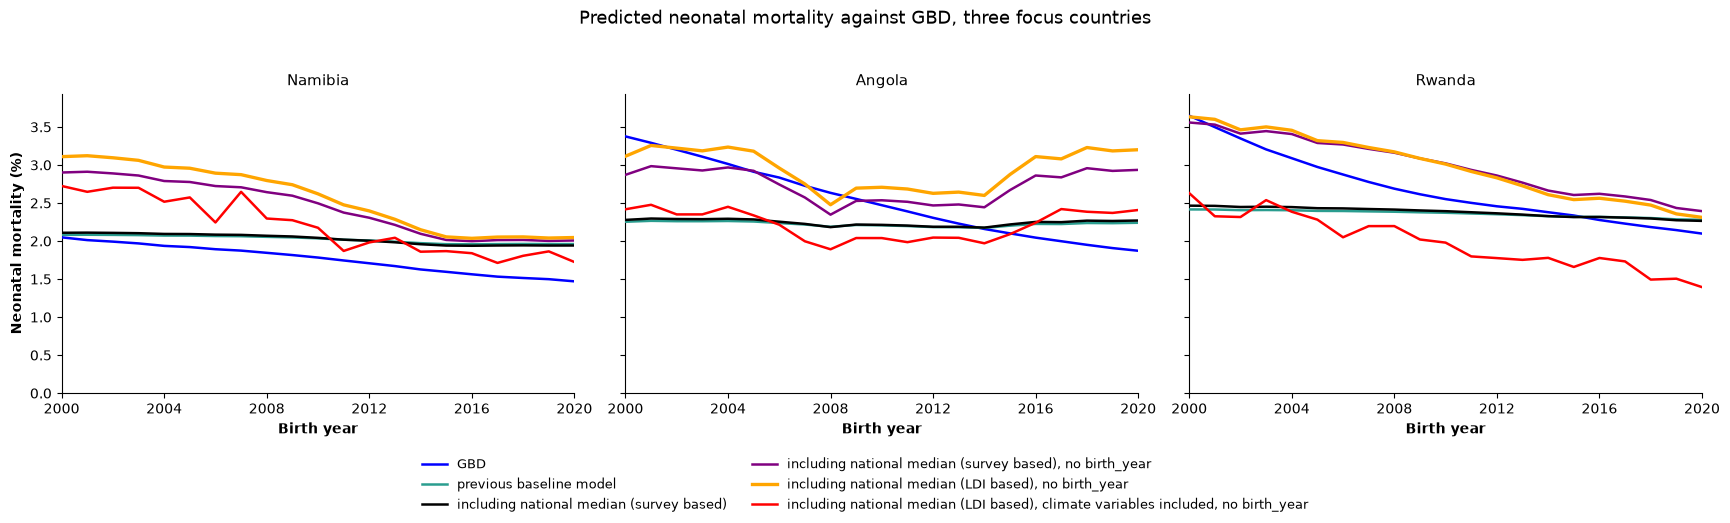

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/gbd_vs_runs_scatter.pdf


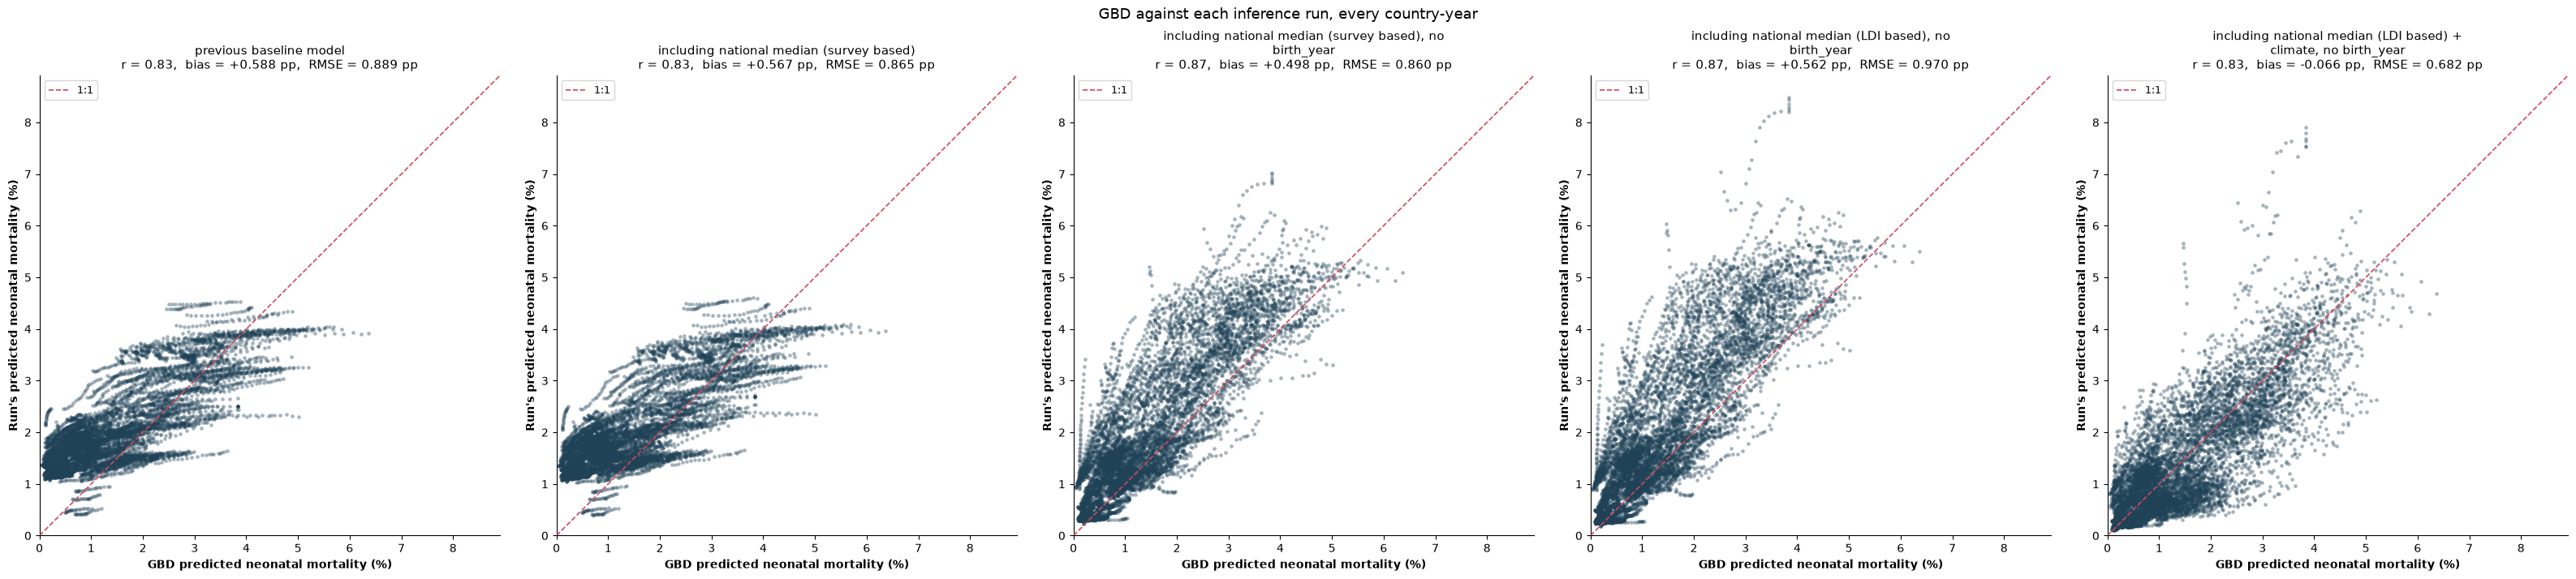


2000 -> 2020 for the focus countries (%):
               gbd_first  gbd_last  i0914_first  i0914_last  i0921_first  i0921_last  i0922a_first  i0922a_last  i0923_first  i0923_last  i0924_first  i0924_last
location_name                                                                                                                                                    
Namibia             2.05      1.47         2.08        1.96         2.11        1.94          2.90         2.01         3.11        2.05         2.72        1.72
Angola              3.38      1.87         2.25        2.24         2.28        2.27          2.87         2.94         3.11        3.20         2.42        2.41
Rwanda              3.65      2.10         2.42        2.28         2.46        2.26          3.56         2.39         3.63        2.31         2.63        1.39

agreement with GBD over all country-years:
  previous baseline model                                  r 0.827  bias +0.588 pp  RMSE 0.889 pp
  inc

In [3]:
# Prediction series against GBD, three focus countries ######################
# Same shape as consumption_rt_predictions: one panel per country, birth year
# on x, predicted neonatal mortality on y, one line per source. All series are
# sex-averaged and, for the inference runs, averaged over draws.
#
# 2026_09_22.01 is the run from model 2026_09_21.02 - the first with
# consumption_pd_national_median in the spec.
import textwrap

R4_COUNTRIES = ["Namibia", "Angola", "Rwanda"]
R4_YEARS = (2000, 2020)
# 09_22a takes purple as asked; 09_14 moves to teal, since it held purple and
# two runs in one colour would be unreadable.
R4_SERIES = {
    "gbd": (GBD_FILE, False, "blue", "GBD"),
    "i0914": (INFERENCE_FILE_09_14, True, "#2a9d8f", "previous baseline model"),
    "i0921": (
        INFERENCE_FILE_09_21,
        True,
        "black",
        "including national median (survey based)",
    ),
    "i0922a": (
        INFERENCE_FILE_09_22,
        True,
        "purple",
        "including national median (survey based), no birth_year",
    ),
    "i0923": (
        INFERENCE_FILE_09_23,
        True,
        "orange",
        "including national median (LDI based), no birth_year",
    ),
    "i0924": (
        INFERENCE_FILE_09_24,
        True,
        "red",
        "including national median (LDI based), climate variables included, no birth_year",
    ),
}
# The newest run carries the heavier line and sits on top.
R4_EMPHASIS = "i0923"


def _r4_mean_draw(frame):
    """Inference files carry either draw columns or a long `draw` column."""
    draw_cols = [c for c in frame.columns if c.startswith("draw_")]
    if draw_cols:
        out = frame[[c for c in frame.columns if "draw_" not in c]].copy()
        out["prevalence"] = frame[draw_cols].mean(axis=1)
        return out
    value_col = "value" if "value" in frame.columns else "prevalence"
    keys = [c for c in ("location_id", "year_id", "sex_id") if c in frame.columns]
    return (
        frame.groupby(keys, as_index=False)[value_col]
        .mean()
        .rename(columns={value_col: "prevalence"})
    )


_r4_key = ["location_id", "year_id", "sex_id"]
r4 = None
for col, (path, is_draws, _c, _l) in R4_SERIES.items():
    f = pd.read_parquet(path).reset_index()
    f = (
        _r4_mean_draw(f).rename(columns={"prevalence": col})
        if is_draws
        else f.rename(columns={"gbd_mean_prevalence": col})
    )
    keys = [k for k in _r4_key if k in f.columns]
    f = f[keys + [col]]
    r4 = f if r4 is None else r4.merge(f, on=keys, how="inner")

r4 = (
    r4.merge(
        locs[["location_id", "location_name"]].drop_duplicates("location_id"),
        on="location_id",
        how="inner",
    )
    .query("year_id >= @R4_YEARS[0] and year_id <= @R4_YEARS[1]")
    .groupby(["location_name", "year_id"], as_index=False)[list(R4_SERIES)]
    .mean()
    .sort_values("year_id")
)
print(
    f"{len(r4):,} country-years across {r4['location_name'].nunique()} countries, "
    f"{R4_YEARS[0]}-{R4_YEARS[1]}, {len(R4_SERIES)} series"
)

# 1. the three focus countries over time #####################################
# One shared y range, computed from the data. Calling set_ylim(0, None) on each
# axis under sharey=True lets the last call win, which sets the range from
# whichever panel happens to be last and draws the taller panels outside the
# axes box - Angola and Rwanda both reach well above Namibia's maximum.
_r4_focus = r4[r4["location_name"].isin(R4_COUNTRIES)]
R4_YMAX = 100 * float(_r4_focus[list(R4_SERIES)].to_numpy().max()) * 1.08

fig, axes = plt.subplots(
    ncols=len(R4_COUNTRIES), figsize=(5.8 * len(R4_COUNTRIES), 5.2), sharey=True
)
axes = np.atleast_1d(axes)
handles, labels = [], []
for ax, country in zip(axes, R4_COUNTRIES):
    block = r4[r4["location_name"] == country].sort_values("year_id")
    for col, (_p, _d, colour, label) in R4_SERIES.items():
        ax.plot(
            block["year_id"],
            100 * block[col],
            color=colour,
            lw=2.4 if col == R4_EMPHASIS else 1.8,
            zorder=4 if col == R4_EMPHASIS else 3,
            label=label,
        )
    ax.set_xlim(*R4_YEARS)
    ax.set_ylim(0, R4_YMAX)
    # Years are integers; the default locator lands on 2002.5, 2007.5 etc.
    ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    ax.set_xlabel("Birth year", fontweight="bold")
    ax.set_title(country, fontsize=11)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if not handles:
        handles, labels = ax.get_legend_handles_labels()
axes[0].set_ylabel("Neonatal mortality (%)", fontweight="bold")
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.suptitle(
    "Predicted neonatal mortality against GBD, three focus countries", fontsize=13
)
fig.tight_layout(rect=(0, 0.13, 1, 0.95))
plot_path = f"{PLOT_OUTPUT}predictions_four_runs_three_countries.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

# 2. GBD against two runs, every country-year ################################
# All countries, not just the three, and shared square axes with a 1:1 line so
# the two panels are directly comparable.
R4_SCATTER = [
    ("i0914", "previous baseline model"),
    ("i0921", "including national median (survey based)"),
    ("i0922a", "including national median (survey based), no birth_year"),
    ("i0923", "including national median (LDI based), no birth_year"),
    ("i0924", "including national median (LDI based) + climate, no birth_year"),
]
_r4_max = float(max(r4["gbd"].max(), *(r4[c].max() for c, _ in R4_SCATTER))) * 105
fig, axes = plt.subplots(ncols=len(R4_SCATTER), figsize=(6.4 * len(R4_SCATTER), 6.8))
for ax, (col, title) in zip(np.atleast_1d(axes), R4_SCATTER):
    ax.plot(
        [0, _r4_max],
        [0, _r4_max],
        color="#d1495b",
        lw=1.2,
        ls="--",
        zorder=3,
        label="1:1",
    )
    ax.scatter(
        100 * r4["gbd"],
        100 * r4[col],
        s=11,
        alpha=0.4,
        color="#1f4257",
        linewidths=0,
        zorder=2,
    )
    ax.set_xlim(0, _r4_max)
    ax.set_ylim(0, _r4_max)
    ax.set_aspect("equal")
    ax.set_xlabel("GBD predicted neonatal mortality (%)", fontweight="bold")
    ax.set_ylabel("Run's predicted neonatal mortality (%)", fontweight="bold")
    _diff = r4[col] - r4["gbd"]
    ax.set_title(
        f"{textwrap.fill(title, 46)}\n"
        f"r = {r4[['gbd', col]].corr().iloc[0, 1]:.2f},  "
        f"bias = {100 * _diff.mean():+.3f} pp,  "
        f"RMSE = {100 * np.sqrt((_diff ** 2).mean()):.3f} pp",
        fontsize=10.5,
    )
    ax.legend(fontsize=9, loc="upper left")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("GBD against each inference run, every country-year", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plot_path = f"{PLOT_OUTPUT}gbd_vs_runs_scatter.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print("\n2000 -> 2020 for the focus countries (%):")
_ends = (
    r4[r4["location_name"].isin(R4_COUNTRIES)]
    .groupby("location_name")
    .agg(**{f"{c}_{w}": (c, w) for c in R4_SERIES for w in ("first", "last")})
    .loc[R4_COUNTRIES]
)
print((100 * _ends).round(2).to_string())
print("\nagreement with GBD over all country-years:")
for col, title in R4_SCATTER:
    _d = r4[col] - r4["gbd"]
    print(
        f"  {title:56s} r {r4[['gbd', col]].corr().iloc[0, 1]:.3f}  "
        f"bias {100 * _d.mean():+.3f} pp  RMSE {100 * np.sqrt((_d ** 2).mean()):.3f} pp"
    )

In [4]:
# The same line charts, every level-3 location, straight to pdf ##############
# Same series, colours and labels as predictions_four_runs_three_countries, one
# panel per country instead of three. Pages are grouped by super_region_name -
# a new page starts at each region rather than letting a region run across a
# page boundary - and countries are alphabetical within a region. Nothing is
# drawn in the notebook; every figure is closed after it is written.
#
# Rebuilt from the source files rather than reusing `r4`, because that frame is
# grouped by location_name and no longer carries location_id, which is what
# level and super_region_name join on.
R4A_PER_PAGE = (3, 3)
R4A_PATH = f"{PLOT_OUTPUT}predictions_runs_all_countries.pdf"

_r4a = None
for col, (path, is_draws, _c, _l) in R4_SERIES.items():
    f = pd.read_parquet(path).reset_index()
    f = (
        _r4_mean_draw(f).rename(columns={"prevalence": col})
        if is_draws
        else f.rename(columns={"gbd_mean_prevalence": col})
    )
    keys = [k for k in _r4_key if k in f.columns]
    f = f[keys + [col]]
    _r4a = f if _r4a is None else _r4a.merge(f, on=keys, how="inner")

r4_all = (
    _r4a.merge(
        locs[
            ["location_id", "location_name", "level", "super_region_name"]
        ].drop_duplicates("location_id"),
        on="location_id",
        how="inner",
    )
    .query("level == 3 and year_id >= @R4_YEARS[0] and year_id <= @R4_YEARS[1]")
    # sex-average, then average any remaining strata within a country-year
    .groupby(
        ["super_region_name", "location_name", "year_id"], as_index=False, observed=True
    )[list(R4_SERIES)]
    .mean()
    .sort_values(["super_region_name", "location_name", "year_id"])
)

_countries = r4_all[["super_region_name", "location_name"]].drop_duplicates()
print(
    f"{_countries['location_name'].nunique()} level-3 locations across "
    f"{_countries['super_region_name'].nunique()} super regions, "
    f"{R4_YEARS[0]}-{R4_YEARS[1]}"
)

_nrow, _ncol = R4A_PER_PAGE
_per_page = _nrow * _ncol
_pages = 0
with PdfPages(R4A_PATH) as pdf:
    for region, block in r4_all.groupby("super_region_name", observed=True, sort=True):
        names = sorted(block["location_name"].unique())
        for start in range(0, len(names), _per_page):
            chunk = names[start : start + _per_page]
            fig, axes = plt.subplots(_nrow, _ncol, figsize=(5.0 * _ncol, 4.2 * _nrow))
            axes = np.atleast_1d(axes).ravel()
            handles, labels = [], []
            for ax, country in zip(axes, chunk):
                panel = block[block["location_name"] == country].sort_values("year_id")
                for col, (_p, _d, colour, label) in R4_SERIES.items():
                    ax.plot(
                        panel["year_id"],
                        100 * panel[col],
                        color=colour,
                        lw=2.0 if col == R4_EMPHASIS else 1.5,
                        zorder=4 if col == R4_EMPHASIS else 3,
                        label=label,
                    )
                ax.set_xlim(*R4_YEARS)
                # Years are integers; the default locator lands on 2002.5 etc.
                ax.xaxis.set_major_locator(MaxNLocator(5, integer=True))
                # Per-panel y range: mortality spans an order of magnitude
                # across countries, so a shared range would flatten most panels.
                ax.set_ylim(
                    0, 100 * float(panel[list(R4_SERIES)].to_numpy().max()) * 1.08
                )
                ax.set_title(country, fontsize=10)
                ax.set_axisbelow(True)
                ax.tick_params(labelsize=8)
                for side in ("top", "right"):
                    ax.spines[side].set_visible(False)
                if not handles:
                    handles, labels = ax.get_legend_handles_labels()
            for ax in axes[len(chunk) :]:
                ax.set_visible(False)
            for ax in axes[: len(chunk)]:
                ax.set_xlabel("Birth year", fontweight="bold", fontsize=9)
            for i in range(0, len(chunk), _ncol):
                axes[i].set_ylabel(
                    "Neonatal mortality (%)", fontweight="bold", fontsize=9
                )

            page_of = f" ({start // _per_page + 1} of {-(-len(names) // _per_page)})"
            fig.suptitle(
                f"{region}{page_of if len(names) > _per_page else ''}", fontsize=13
            )
            fig.legend(
                handles, labels, loc="lower center", ncol=2, fontsize=9, frameon=False
            )
            fig.tight_layout(rect=(0, 0.12, 1, 0.95))
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)
            _pages += 1

print(f"Saved {R4A_PATH} ({_pages} pages)")

193 level-3 locations across 7 super regions, 2000-2020
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/predictions_runs_all_countries.pdf (25 pages)
